# Control óptimo para la transición energética en un modelo de evaluación integrada

**MA4703 Control Óptimo - Departamento de Ingeniería Matemática - Facultad de Ciencias Físicas y Matemáticas, Universidad de Chile**

_María Rubio & Ignacio Romero Orrego_

Este notebook estudia un modelo macroeconómico–climático con dos fuentes de energía (fósil y renovable) y determina la política óptima de transición energética. Es autosuficiente: contiene el análisis del sistema, la formulación del problema de control óptimo, su resolución numérica con `OptimalControl.jl` + `Ipopt`, el contraste con el Principio del Máximo de Pontryagin (En adelante: PMP) y con la ecuación de Hamilton–Jacobi–Bellman (En adelante: HJB).

## Contenido
1. Configuración y parámetros
2. Modelo y análisis cualitativo (estrategias, positividad, cota del carbono, equilibrios)
3. Linealización: controlabilidad y observabilidad local
4. Problema de control óptimo y condiciones del PMP
5. Solución numérica con `OptimalControl.jl`
6. Escenarios climáticos y de política
7. Convergencia de malla
8. Función valor y ecuación HJB
9. Conclusiones

> El desarrollo teórico en profundidad está presente en el informe asociado.

## 1. Configuración y parámetros

**Instalación**: `DifferentialEquations`, `Plots`, `OptimalControl`, `NLPModelsIpopt` e `Ipopt`. `LinearAlgebra` y `Printf` vienen con Julia. Probado con Julia 1.12 y `OptimalControl` 2.0.4.

Los parámetros y las funciones de producción y consumo son ilustrativos: se eligieron para obtener un sistema sencillo con trayectorias no negativas y un equilibrio positivo bajo ciertos controles.

In [ ]:
# Instalación de paquetes
using Pkg
Pkg.add(["DifferentialEquations", "Plots", "OptimalControl", "NLPModelsIpopt", "Ipopt"])

In [ ]:
using DifferentialEquations
using LinearAlgebra
using Plots
using OptimalControl
using NLPModelsIpopt
using Ipopt
using Printf

In [ ]:
# ── Parámetros del modelo ──────────────────────────────────────────────────
const a     = 0.65     # factor productivo
const eta   = 1.20     # productividad relativa de la energía renovable
const c     = 0.20     # tasa de consumo, C(t) = c k(t)
const delta = 0.10     # depreciación del capital
const beta  = 0.20     # emisiones asociadas a u1
const sigma = 0.12     # absorción natural de carbono
const U1MAX = 1.0      # cota del control fósil
const U2MAX = 1.0      # cota del control renovable
const K_EXT_MIN = -0.5
@assert K_EXT_MIN > -1.0 && 1 + c * K_EXT_MIN > 0

# ── Parámetros del criterio de bienestar ───────────────────────────────────
const rho   = 0.03     # tasa de descuento social
const CHI   = 0.20     # daño climático (caso base)
const q1    = 0.08     # costo cuadrático del uso fósil
const q2    = 0.12     # costo cuadrático de la inversión renovable

# ── Horizonte y condición inicial ──────────────────────────────────────────
const T  = 30.0
const x0 = [1.0, 0.8]  # (capital inicial, carbono inicial)

# Carpeta de salida para las figuras
const FIG = "figuras"
mkpath(FIG)
default(lw = 2, grid = true, legend = :best, framestyle = :box)

# Paleta basada en viridis (se omite el extremo amarillo, que se pierde sobre fondo blanco)
const PAL   = ["#440154", "#3B528B", "#21908C", "#5DC863", "#AADC32"]
const COL_K = PAL[3]   # capital / renovable
const COL_M = PAL[1]   # carbono / fósil

"#440154"

## 2. Modelo y análisis cualitativo

El capital $k(t)$ y el carbono acumulado $M(t)$ evolucionan según

$$
\dot k = Y(k,u_1,u_2) - C(t) - \delta k,\qquad \dot M = \beta u_1 - \sigma M,
\qquad 0\le u_1\le u_{1,\max},\quad 0\le u_2\le u_{2,\max},
$$

con $u_1$ el uso de energía fósil y $u_2$ el de energía renovable. Se consideran

$$
Y(k,u_1,u_2) = a\frac{k}{1+k}(u_1+\eta u_2),\qquad C(t)=c\,k(t),
$$

de modo que $\;\dot k = a\frac{k}{1+k}(u_1+\eta u_2)-(c+\delta)k$.

### 2.1 Tres estrategias energéticas admisibles
Se simula el sistema bajo tres controles que cumplen las restricciones $0\le u_1,u_2\le 1$, solo para comparar el comportamiento (no se sabe, a priori, que sean óptimos):

| Estrategia | $u_1(t)$ | $u_2(t)$ |
|---|---|---|
| Fósil sostenido | $0.70$ | $0.20$ |
| Transición gradual | $0.70-0.55\,\dfrac{t}{T}$ | $0.20+0.60\,\dfrac{t}{T}$ |
| Mayor uso renovable | $0.35$ | $0.80$ |

Se grafica su efecto sobre los estados.

In [ ]:
produccion(k, u1, u2) = a * (k / (1 + k)) * (u1 + eta * u2)
consumo(k) = c * k

# Campo vectorial f(x, u) con x = (k, M), u = (u1, u2)
dinamica(x, u) = [produccion(x[1], u[1], u[2]) - consumo(x[1]) - delta * x[1],
                  beta * u[1] - sigma * x[2]]

println("Estado inicial: x0 = ", x0)
println("f(x0, (0.7, 0.2)) = ", dinamica(x0, (0.7, 0.2)))

Estado inicial: x0 = [1.0, 0.8]
f(x0, (0.7, 0.2)) = [0.005499999999999977, 0.043999999999999984]


In [ ]:
control_constante(u1, u2) = t -> (u1, u2)

function control_transicion(t)
    s = clamp(t / T, 0.0, 1.0)
    return (0.70 - 0.55 * s, 0.20 + 0.60 * s)
end

estrategias = [
    ("Fósil sostenido",    control_constante(0.70, 0.20)),
    ("Transición gradual", control_transicion),
    ("Mayor renovable",    control_constante(0.35, 0.80)),
]

function modelo!(dx, x, u, t)
    u1, u2 = u(t)
    dx[1] = produccion(x[1], u1, u2) - consumo(x[1]) - delta * x[1]
    dx[2] = beta * u1 - sigma * x[2]
    return nothing
end

function simular(u, x_inicial; paso = 0.1)
    prob = ODEProblem(modelo!, Float64.(x_inicial), (0.0, T), u)
    return solve(prob, Tsit5(); saveat = paso, reltol = 1e-9, abstol = 1e-9)
end

res_est = Dict{String,Any}()
for (nombre, u) in estrategias
    res_est[nombre] = simular(u, x0)
    sol_e = res_est[nombre]
    println(rpad(nombre, 20), " → k(T) = ", round(sol_e.u[end][1]; digits = 4),
            ";  M(T) = ", round(sol_e.u[end][2]; digits = 4))
end

Fósil sostenido      → k(T) = 1.0363;  M(T) = 1.1566
Transición gradual   → k(T) = 1.3318;  M(T) = 0.4877
Mayor renovable      → k(T) = 1.8353;  M(T) = 0.5893


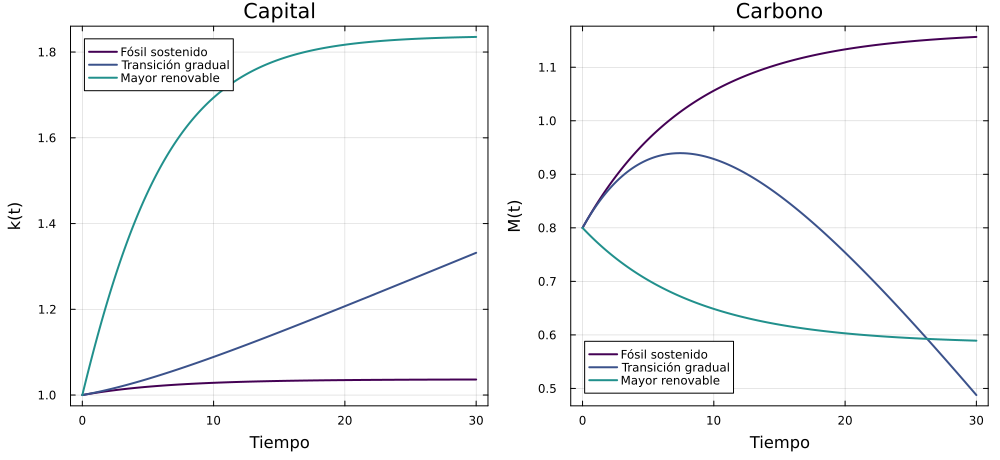

In [ ]:
fig_k = plot(xlabel = "Tiempo", ylabel = "k(t)", title = "Capital")
fig_M = plot(xlabel = "Tiempo", ylabel = "M(t)", title = "Carbono")

for (i, (nombre, _)) in enumerate(estrategias)
    datos = Array(res_est[nombre])          # fila 1: k; fila 2: M
    plot!(fig_k, res_est[nombre].t, datos[1, :]; label = nombre, color = PAL[i])
    plot!(fig_M, res_est[nombre].t, datos[2, :]; label = nombre, color = PAL[i])
end

fig_estrategias = plot(fig_k, fig_M; layout = (1, 2), size = (1000, 460),
                       left_margin = 5 * Plots.mm, bottom_margin = 5 * Plots.mm)
savefig(fig_estrategias, joinpath(FIG, "estrategias_estados.png"))
display(fig_estrategias)

### 2.2 Positividad y cota del carbono

Si $M(0)\ge 0$ y $u_1\ge 0$, la ecuación $\dot M=\beta u_1-\sigma M$ mantiene $M(t)\ge 0$. Además, como $u_1\le u_{1,\max}$, por comparación

$$
0\le M(t)\le M(0)e^{-\sigma t}+\frac{\beta u_{1,\max}}{\sigma}\big(1-e^{-\sigma t}\big),
$$

es decir, el carbono no crece indefinidamente. Para la producción elegida, $k=0$ es solución, así que con $k(0)\ge 0$ el capital también se mantiene no negativo. Se verifica numéricamente en las tres estrategias.

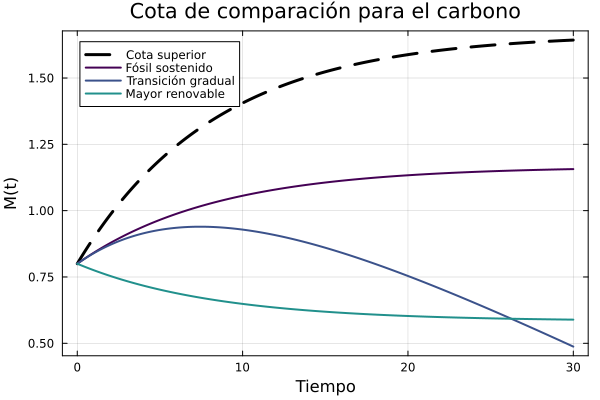

Error máximo entre M numérico y fórmula exacta: 9.937228817591404e-11


In [ ]:
# Cota uniforme para M(t), válida para todo control admisible
cota_M(t) = x0[2] * exp(-sigma * t) + (beta * U1MAX / sigma) * (1 - exp(-sigma * t))

tgrid  = collect(range(0.0, T; length = 301))
p_cota = plot(tgrid, cota_M.(tgrid); label = "Cota superior", lw = 3, linestyle = :dash, color = :black,
              xlabel = "Tiempo", ylabel = "M(t)", title = "Cota de comparación para el carbono")

for (i, (nombre, _)) in enumerate(estrategias)
    sol_e = res_est[nombre]
    plot!(p_cota, sol_e.t, Array(sol_e)[2, :]; label = nombre, color = PAL[i])

    @assert minimum(Array(sol_e)[1, :]) >= -1e-8                 # k ≥ 0
    @assert minimum(Array(sol_e)[2, :]) >= -1e-8                 # M ≥ 0
    @assert all(Array(sol_e)[2, :] .<= cota_M.(sol_e.t) .+ 1e-7) # M ≤ cota
end
savefig(p_cota, joinpath(FIG, "cota_carbono.png"))
display(p_cota)

# Para u1 constante, M(t) tiene solución exacta: comprobación del integrador
u1_prueba = 0.70
M_estrella_prueba = beta * u1_prueba / sigma
M_exacto(t) = M_estrella_prueba + (x0[2] - M_estrella_prueba) * exp(-sigma * t)

sol_prueba = res_est["Fósil sostenido"]
error_M = maximum(abs.(Array(sol_prueba)[2, :] .- M_exacto.(sol_prueba.t)))
println("Error máximo entre M numérico y fórmula exacta: ", error_M)
@assert error_M < 1e-5

### 2.3 Estados estacionarios

Para controles constantes $u^*=(u_1^*,u_2^*)$, los equilibrios satisfacen

$$
Y(k^*,u_1^*,u_2^*)=C^*+\delta k^*,\qquad M^*=\frac{\beta}{\sigma}u_1^*.
$$

Con las funciones del modelo existe un equilibrio con $k^*=0$ y otro con capital positivo cuando

$$
k^*=\frac{a(u_1^*+\eta u_2^*)}{c+\delta}-1>0 .
$$

Se toma $u^*=(0.35,\,0.60)$ como punto de linealización.

In [ ]:
u_estrella = (0.35, 0.60)

function equilibrio_positivo(u)
    u1, u2 = u
    kstar = a * (u1 + eta * u2) / (c + delta) - 1
    kstar > 0 || error("Este control no da un equilibrio con k* > 0.")
    return [kstar, beta * u1 / sigma]
end

x_estrella = equilibrio_positivo(u_estrella)
println("u* = ", u_estrella)
println("Equilibrio positivo x* = ", round.(x_estrella; digits = 6))
println("f(x*, u*) = ", dinamica(x_estrella, u_estrella))
@assert norm(dinamica(x_estrella, u_estrella)) < 1e-10

# Otra rama de equilibrio, con capital nulo
x_equilibrio_cero = [0.0, beta * u_estrella[1] / sigma]
@assert norm(dinamica(x_equilibrio_cero, u_estrella)) < 1e-10
println("Equilibrio con capital nulo: ", x_equilibrio_cero)

u* = (0.35, 0.6)
Equilibrio positivo x* = [1.318333, 0.583333]
f(x*, u*) = [5.551115123125783e-17, 0.0]
Equilibrio con capital nulo: [0.0, 0.5833333333333333]


## 3. Linealización: controlabilidad y observabilidad local

Alrededor de $(x^*,u^*)$ se escribe $\dot\xi = A\xi + Bv$, con $\xi=x-x^*$, $v=u-u^*$, donde

$$
A=\begin{pmatrix}\dfrac{a(u_1^*+\eta u_2^*)}{(1+k^*)^2}-(c+\delta)&0\\[2mm]0&-\sigma\end{pmatrix},\qquad
B=\begin{pmatrix}\dfrac{a k^*}{1+k^*}&\dfrac{a\eta k^*}{1+k^*}\\[2mm]\beta&0\end{pmatrix}.
$$

- **Controlabilidad (Kalman):** $\operatorname{rg}[B\;\;AB]=2$.
- **Observabilidad:** con salidas medibles $y=(C,\,M)=(ck,\,M)$, es decir $H=\begin{pmatrix}c&0\\0&1\end{pmatrix}$, se verifica $\operatorname{rg}\begin{pmatrix}H\\HA\end{pmatrix}=2$.
- **Estabilidad:** los autovalores de $A$ determinan la estabilidad local del equilibrio bajo $u=u^*$.

In [ ]:
function jacobianos(x, u)
    k, M = x
    u1, u2 = u
    A = [a * (u1 + eta * u2) / (1 + k)^2 - c - delta   0.0;
         0.0                                           -sigma]
    B = [a * k / (1 + k)   a * eta * k / (1 + k);
         beta              0.0]
    return A, B
end

A, B = jacobianos(x_estrella, u_estrella)
K    = hcat(B, A * B)                    # matriz de Kalman [B | AB], 2×4

# Observabilidad con salidas y = (c k, M)
H = [c 0.0; 0.0 1.0]
O = vcat(H, H * A)

println("A = ");        display(A)
println("B = ");        display(B)
println("K = [B | AB] = "); display(K)
println("Rango de controlabilidad = ", rank(K), "   (dim. del estado = 2)")
println("Rango de observabilidad  = ", rank(O), "   (dim. del estado = 2)")
println("Autovalores de A = ", eigvals(A))
println("Equilibrio localmente asintóticamente estable (u = u*): ", all(real.(eigvals(A)) .< 0))

@assert rank(K) == 2
@assert rank(O) == 2

A = 


2×2 Matrix{Float64}:
 -0.170597   0.0
  0.0       -0.12

B = 


2×2 Matrix{Float64}:
 0.369626  0.443551
 0.2       0.0

K = [B | AB] = 


2×4 Matrix{Float64}:
 0.369626  0.443551  -0.063057  -0.0756684
 0.2       0.0       -0.024      0.0

Rango de controlabilidad = 2   (dim. del estado = 2)
Rango de observabilidad  = 2   (dim. del estado = 2)
Autovalores de A = [-0.1705966930265995, -0.12]
Equilibrio localmente asintóticamente estable (u = u*): true


## 4. Problema de control óptimo y condiciones del PMP

En el sistema económico se maximiza el bienestar social descontado
$$
\max_{u(\cdot)}\; J=\int_0^T e^{-\rho t}\,\mathcal U\big(C(t),M(t)\big)\,dt,
$$
con utilidad instantánea de consumo y daño climático $\;\mathcal U(C,M)=\log(1+C)-\tfrac{\chi}{2}M^2$, donde $C=ck$, más costos cuadráticos de ajuste de los controles. Explícitamente,
$$
J=\int_0^T e^{-\rho t}\Big[\log(1+ck)-\tfrac{\chi}{2}M^2-\tfrac{q_1}{2}u_1^2-\tfrac{q_2}{2}u_2^2\Big]dt .
$$
Los costos $q_1,q_2>0$ regularizan el problema: hacen que el máximo del Hamiltoniano respecto de $u$ sea único.

Las restricciones son: $x(0)=x_0$, estado final libre y $k,M\ge 0$ (que se cumplen automáticamente).

El espacio de controles admisibles es: $\mathcal A=\{u:[0,T]\to\mathbb R^2 \text{ medible},\; u(t)\in U \text{ c.t.p.}\}$, con $U=[0,u_{1,\max}]\times[0,1]$ compacto y convexo.

Luego el Hamiltoniano es, con $g(k)=a\,k/(1+k)$:

$$
H=e^{-\rho t}\Big[\log(1+ck)-\tfrac{\chi}{2}M^2-\tfrac{q_1}{2}u_1^2-\tfrac{q_2}{2}u_2^2\Big]
+\lambda_k\big[g(k)(u_1+\eta u_2)-(c+\delta)k\big]+\lambda_M\big[\beta u_1-\sigma M\big].
$$

Los co-estados y la transversalidad entregan:
$$
\dot\lambda_k=-e^{-\rho t}\frac{c}{1+ck}-\lambda_k\Big[\frac{a(u_1+\eta u_2)}{(1+k)^2}-(c+\delta)\Big],\qquad
\dot\lambda_M=\chi e^{-\rho t}M+\sigma\lambda_M,\qquad \lambda(T)=0 .
$$

Para la maximización de $H$ notamos que es separable y estrictamente cóncava en $u$, por lo que el óptimo es una proyección sobre las cotas. Con los co-estados en valor corriente $\mu=e^{\rho t}\lambda$:

$$
u_1^*=\Pi_{[0,u_{1,\max}]}\!\Big(\frac{g(k)\mu_k+\beta\mu_M}{q_1}\Big),\qquad
u_2^*=\Pi_{[0,1]}\!\Big(\frac{\eta\,g(k)\mu_k}{q_2}\Big).
$$

Como $\mu_M<0$, el término $\beta\mu_M$ es el costo climático del uso fósil, y $\mathrm{SCC}=-\mu_M/\mu_k$ es el _costo social del carbono_ (en unidades de capital). En valor corriente, el sistema adjunto es autónomo:

$$
\dot\mu_k=\Big(\rho+c+\delta-\tfrac{a(u_1+\eta u_2)}{(1+k)^2}\Big)\mu_k-\tfrac{c}{1+ck},\qquad
\dot\mu_M=(\rho+\sigma)\mu_M+\chi M,\qquad \mu(T)=0 .
$$

## 5. Solución numérica con `OptimalControl.jl`

`construir_ocp` define el problema con `@def` para un daño climático `chi`, una cota fósil `u1max` y cotas de estado `Mcap`, `Kcap`. Las cotas $k\le K_{cap}$ y $M\le M_{cap}$ son "cajas de seguridad" que **no** están activas en el caso base. Con `Mcap = 0.85` se obtiene el escenario con restricción de estado $M\le 0.85$.

Se usan las funciones sin regularizar: con $k\ge 0$ se cumple $1+k>0$ y $1+ck>0$. Si apareciera un `DomainError`, puede regularizarse el logaritmo y el cociente $k/(1+k)$ con un pequeño $\varepsilon$.

In [ ]:
function construir_ocp(; chi = CHI, u1max = 1.0, Mcap = 1.85, Kcap = 4.2)
    @def begin
        t ∈ [0.0, T], time
        x = (k, M) ∈ R², state
        u = (u1, u2) ∈ R², control

        x(0.0) == x0

        0 <= u1(t) <= u1max
        0 <= u2(t) <= 1
        0 <= k(t) <= Kcap
        0 <= M(t) <= Mcap

        ẋ(t) == [a * max(k(t), K_EXT_MIN) /(1 + max(k(t), K_EXT_MIN)) * (u1(t) + eta * u2(t)) - (c + delta) * k(t),
                 beta * u1(t) - sigma * M(t)]

        ∫( exp(-rho * t) * ( log(1 + c * max(k(t), K_EXT_MIN)) - chi * M(t)^2 / 2 -
                             q1 * u1(t)^2 / 2 - q2 * u2(t)^2 / 2 ) ) → max
    end
end

construir_ocp (generic function with 1 method)

`solve(ocp; grid_size = N, init = ..., display = ...)` discretiza el problema y lo resuelve con Ipopt a través de `NLPModelsIpopt`. Si fuera necesario, se pueden pasar opciones de Ipopt como `max_iter` o `tol`.

In [ ]:
function resolver_ocp(; chi = CHI, u1max = 1.0, Mcap = 1.85, N = 240, verbose = false)
    ocp = construir_ocp(; chi, u1max, Mcap)
    sol = solve(ocp; grid_size = N,
                     init = (state = x0, control = [0.5, 0.8]),
                     display = verbose)
    OptimalControl.successful(sol) || @warn "Ipopt no reportó convergencia" chi u1max Mcap
    return sol
end

resolver_ocp (generic function with 1 method)

### Co-estados y controles según el PMP

Se implementan los controles que dicta el PMP y el sistema adjunto en valor corriente, integrado hacia atrás con RK4 desde $\mu(T)=0$ usando $x(t)$ y $u(t)$ de la solución numérica. Esto permite contrastar, sobre una misma solución, el co-estado que entrega el solver con el que exige el PMP.

In [ ]:
# Controles que impone el PMP (maximización de H, separable y estrictamente cóncava en u).
#   g(k)  = a k/(1+k)        μ = e^{ρt} λ   (co-estados en valor corriente)
g(k) = a * k / (1 + k)
u1_pmp(k, mk, mM; u1max = 1.0) = clamp((g(k) * mk + beta * mM) / q1, 0.0, u1max)
u2_pmp(k, mk)                  = clamp(eta * g(k) * mk / q2, 0.0, 1.0)

u2_pmp (generic function with 1 method)

In [ ]:
# Integra hacia atrás, con RK4, el sistema adjunto en valor corriente
#   μk' = (ρ + c + δ - a(u1+η u2)/(1+k)²) μk - c/(1+ck)
#   μM' = (ρ + σ) μM + χ M                       con  μ(T) = 0 (estado final libre)
# sobre la malla ts (ascendente) usando x(t), u(t) de la solución numérica.
function adjunto_pmp(xf, uf, ts; chi = CHI)
    F(t, m) = begin
        t = clamp(t, 0.0, T)                # evita salir del dominio por redondeo
        k, M = xf(t); v1, v2 = uf(t)
        [(rho + c + delta - a * (v1 + eta * v2) / (1 + k)^2) * m[1] - c / (1 + c * k),
         (rho + sigma) * m[2] + chi * M]
    end
    n  = length(ts)
    mu = zeros(2, n)                       # mu[:, n] = μ(T) = 0
    for j in n:-1:2
        h  = ts[j-1] - ts[j]               # h < 0 (integración hacia atrás)
        t  = ts[j];  y = mu[:, j]
        k1 = F(t, y)
        k2 = F(t + h / 2, y + h / 2 * k1)
        k3 = F(t + h / 2, y + h / 2 * k2)
        k4 = F(t + h,     y + h * k3)
        mu[:, j-1] = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    end
    return mu
end

adjunto_pmp (generic function with 1 method)

`postproceso` muestrea la solución en una malla fina y calcula: el bienestar $J$ (regla del trapecio), los co-estados reconstruidos con el PMP en valor corriente $\mu$ y valor presente $\lambda=e^{-\rho t}\mu$, el co-estado del solver (alineado en signo, pues su convención depende de la versión instalada) con su desajuste relativo, y los controles que dicta el PMP.

In [ ]:
function postproceso(sol; chi = CHI, u1max = 1.0, npts = 1201)
    xf, uf, pf = state(sol), control(sol), costate(sol)
    ts = collect(range(0.0, T; length = npts))

    X = reduce(hcat, [xf(t) for t in ts])          # 2 × npts : (k; M)
    U = reduce(hcat, [uf(t) for t in ts])          # 2 × npts : (u1; u2)
    P = reduce(hcat, [pf(t) for t in ts])          # 2 × npts : co-estado entregado por el solver
    k, M, u1, u2 = X[1, :], X[2, :], U[1, :], U[2, :]

    # Bienestar J por la regla del trapecio (independiente de la convención de signo del solver)
    L  = @. exp(-rho * ts) * (log(1 + c * k) - chi * M^2 / 2 - q1 * u1^2 / 2 - q2 * u2^2 / 2)
    J  = sum((L[1:end-1] .+ L[2:end]) .* diff(ts)) / 2

    # J que entrega el solver: es consistente con la discretización y es el valor que se reporta.
    # (El J anterior re-integra la solución interpolada y difiere ~1e-4.)
    Jsol = try OptimalControl.objective(sol) catch; J end
    abs(Jsol - J) > 0.05 * abs(J) && (Jsol = J)   # protección ante otra convención de signo

    # Co-estados reconstruidos con el PMP (valor corriente μ y valor presente λ = e^{-ρt} μ)
    mu  = adjunto_pmp(xf, uf, ts; chi)
    lam = mu .* exp.(-rho .* ts)'

    # El signo del co-estado del solver depende de la convención de la versión instalada
    # (min vs max, p⁰ = ±1). Se alinea con la reconstrucción PMP y se informa el desajuste.
    s = sign(sum(P .* lam)); s == 0 && (s = 1.0)
    P = s .* P
    desajuste = maximum(abs.(P .- lam)) / max(maximum(abs.(lam)), eps())

    # Controles que dicta el PMP con los co-estados reconstruidos
    u1r = [u1_pmp(k[i], mu[1, i], mu[2, i]; u1max) for i in eachindex(ts)]
    u2r = [u2_pmp(k[i], mu[1, i])                  for i in eachindex(ts)]

    return (; ts, k, M, u1, u2, J, Jsol, mu, lam, P, u1r, u2r, desajuste, signo = s,
              scc = -mu[2, :] ./ mu[1, :])          # costo social del carbono (en unidades de capital)
end

postproceso (generic function with 1 method)

### Caso base

Se resuelve con $N=240$ nodos y se informan los indicadores de verificación: bienestar, estados finales, co-estados iniciales y costo social del carbono, desajuste entre el co-estado del solver y el del PMP, diferencia entre los controles numéricos y los dictados por el PMP, e instante en que la inversión renovable deja la cota $u_2=1$.

In [ ]:
sol  = resolver_ocp(verbose = true)
base = postproceso(sol)

@printf("\nConvergió: %s\n", OptimalControl.successful(sol))
@printf("J (solver, objective) = %.6f   <- valor reportado\n", base.Jsol)
@printf("J (trapecio, post-proceso) = %.6f   (difiere ~1e-4 por la re-integración)\n", base.J)
@printf("k(T) = %.4f   M(T) = %.4f\n", base.k[end], base.M[end])
@printf("μk(0) = %.4f   μM(0) = %.4f   SCC(0) = %.3f\n", base.mu[1, 1], base.mu[2, 1], base.scc[1])
@printf("Desajuste co-estado solver vs. PMP (relativo) = %.2e   [signo aplicado: %+d]\n",
        base.desajuste, Int(base.signo))
@printf("max|u1 - u1_PMP| = %.3e    max|u2 - u2_PMP| = %.3e\n",
        maximum(abs.(base.u1 .- base.u1r)), maximum(abs.(base.u2 .- base.u2r)))
# Instante en que la inversión renovable deja la cota u2 = 1
idx = findfirst(<(1 - 1e-4), base.u2)
idx === nothing || @printf("u2 = 1 hasta t ≈ %.2f\n", base.ts[idx])

▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 240)
   ├─ Modeler: adnlp
   └─ Solver: ipopt

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     1682
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:     2402

Total number of variables............................:      962
                     variables with only lower bounds:        0
                variables with lower and upper bounds:      962
                     variables with only upper bounds:        0
Total number of equality constraints.................:      482
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints

### Trayectorias óptimas

Estados $k(t)$, $M(t)$; co-estados en valor presente $\lambda=e^{-\rho t}\mu$ (sólida: PMP; punteada: solver); controles $u_1$, $u_2$ (sólida: numérico; punteada: reconstruido con el PMP); y costo social del carbono $-\mu_M/\mu_k$.

_Nota:_ el gráfico nativo `plot(sol)` dibuja el co-estado con la convención de signo de `OptimalControl.jl`, opuesta a la del PMP en valor presente que se usa aquí; en las figuras propias el signo se alinea con la reconstrucción del PMP.


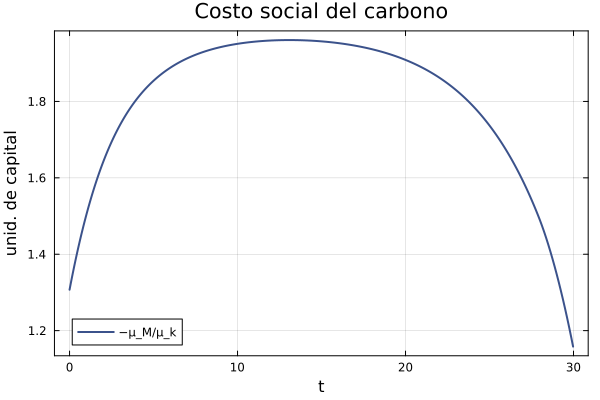

In [ ]:
default(lw = 2, grid = true, legend = :best, framestyle = :box)

# 6.1 Estados
p_k = plot(base.ts, base.k; label = "k(t)", xlabel = "t", ylabel = "Capital", title = "Estado: capital",
            color = COL_K)
p_M = plot(base.ts, base.M; label = "M(t)", xlabel = "t", ylabel = "Carbono", title = "Estado: carbono",
           color = COL_M)

# 6.2 Co-estados (valor presente λ = e^{-ρt} μ). Línea sólida: PMP; punteada: solver
p_lk = plot(base.ts, base.lam[1, :]; label = "λ_k  (PMP)", xlabel = "t", ylabel = "λ_k",
            title = "Co-estado del capital", color = COL_K)
plot!(p_lk, base.ts, base.P[1, :]; label = "λ_k  (solver)", ls = :dash, color = :black)
p_lM = plot(base.ts, base.lam[2, :]; label = "λ_M  (PMP)", xlabel = "t", ylabel = "λ_M",
            title = "Co-estado del carbono", color = COL_M)
plot!(p_lM, base.ts, base.P[2, :]; label = "λ_M  (solver)", ls = :dash, color = :black)

# 6.3 Controles (sólida: solución numérica; punteada: reconstruida con el PMP)
p_u1 = plot(base.ts, base.u1; label = "u₁ numérico", xlabel = "t", ylabel = "u₁",
            title = "Control: extracción fósil", ylims = (-0.02, 1.02), color = COL_M)
plot!(p_u1, base.ts, base.u1r; label = "u₁ PMP", ls = :dash, color = :black)
p_u2 = plot(base.ts, base.u2; label = "u₂ numérico", xlabel = "t", ylabel = "u₂",
            title = "Control: inversión renovable", ylims = (-0.02, 1.02), color = COL_K)
plot!(p_u2, base.ts, base.u2r; label = "u₂ PMP", ls = :dash, color = :black)

# 6.4 Costo social del carbono  SCC = -μM/μk
p_scc = plot(base.ts[1:end-1], base.scc[1:end-1]; label = "−μ_M/μ_k", xlabel = "t",
             ylabel = "unid. de capital", title = "Costo social del carbono", color = PAL[2])

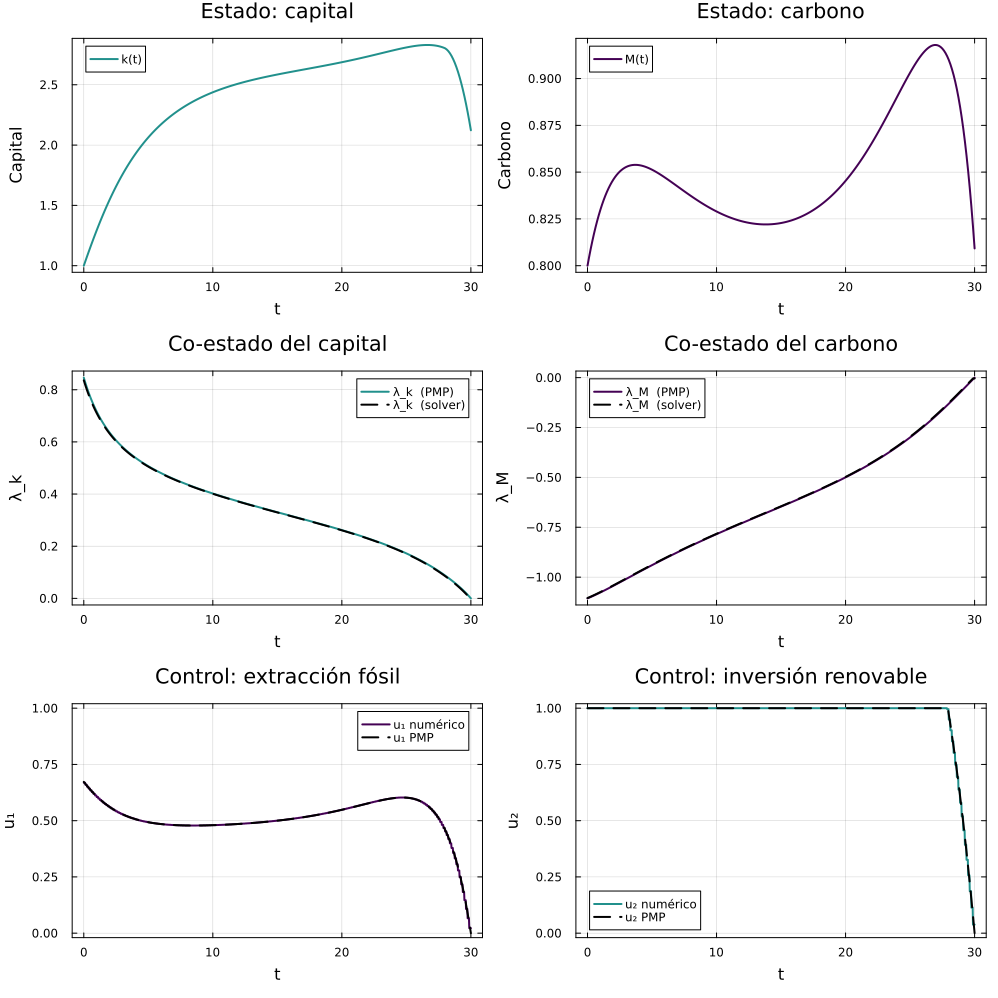

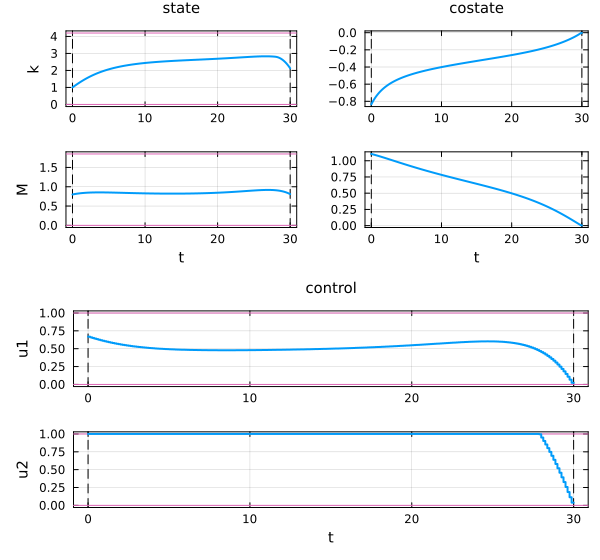

In [ ]:
fig_estados   = plot(p_k, p_M;    layout = (1, 2), size = (900, 340))
fig_costados  = plot(p_lk, p_lM;  layout = (1, 2), size = (900, 340))
fig_controles = plot(p_u1, p_u2;  layout = (1, 2), size = (900, 340))
fig_total     = plot(p_k, p_M, p_lk, p_lM, p_u1, p_u2; layout = (3, 2), size = (1000, 1000))

savefig(fig_estados, joinpath(FIG, "fig_estados.png"))
savefig(fig_costados, joinpath(FIG, "fig_coestados.png"))
savefig(fig_controles, joinpath(FIG, "fig_controles.png"))
savefig(p_scc, joinpath(FIG, "fig_scc.png"))
savefig(fig_total, joinpath(FIG, "fig_trayectorias_optimas.png"))
display(fig_total)

# Gráfico nativo de OptimalControl.jl (estado, co-estado y control en un solo panel)
fig_nativo = plot(sol)
savefig(fig_nativo, joinpath(FIG, "fig_nativo_OptimalControl.png"))
display(fig_nativo)

## 6. Escenarios climáticos y de política

| Escenario | Qué cambia |
|---|---|
| Base | $\chi = 0.20$ |
| Daño alto | $\chi = 0.70$ |
| Daño bajo | $\chi = 0.04$ |
| Tope fósil | $u_1\le 0.5$ |
| Tope de carbono | $M\le 0.85$ (restricción de estado) |

En el escenario con tope de carbono, el sistema adjunto de la sección 5 no incluye el multiplicador (medida) de la restricción de estado, por lo que allí solo se reportan $J$, $k(T)$, $M(T)$ y el máximo de $M$.


Escenario                           J       k(T)    M(T)   max M
Base (χ = 0.20)                  4.7194   2.1229  0.8092  0.9179
Daño alto (χ = 0.70)             3.2224   1.5842  0.3169  0.8000
Daño bajo (χ = 0.04)             6.8676   2.8222  1.4540  1.6352
Tope fósil (u₁ ≤ 0.5)            4.7140   2.0673  0.7574  0.8322
Tope de carbono (M ≤ 0.85)       4.7176   2.0795  0.7694  0.8500


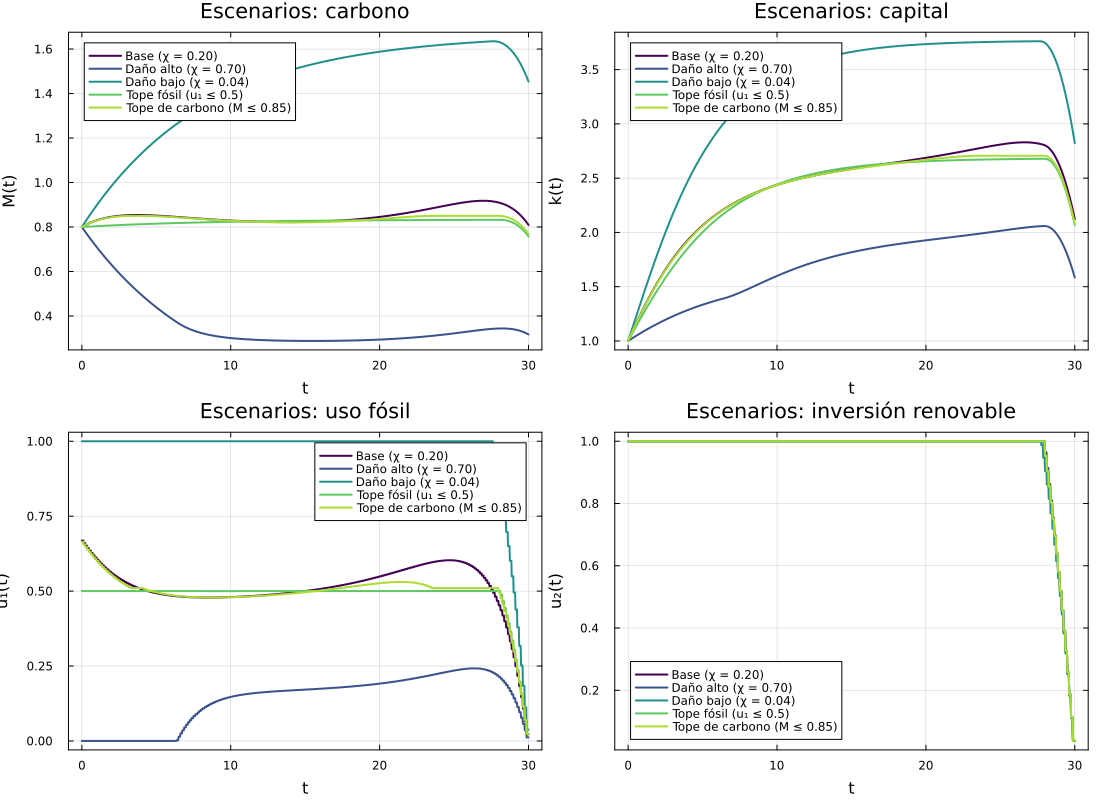

In [ ]:
escenarios = [
    ("Base (χ = 0.20)",         (chi = 0.20,)),
    ("Daño alto (χ = 0.70)",    (chi = 0.70,)),
    ("Daño bajo (χ = 0.04)",    (chi = 0.04,)),
    ("Tope fósil (u₁ ≤ 0.5)",   (u1max = 0.5,)),
    ("Tope de carbono (M ≤ 0.85)", (Mcap = 0.85,)),
]

resultados = Dict{String,Any}()
println("\n", rpad("Escenario", 30), "      J       k(T)    M(T)   max M")
for (nombre, kw) in escenarios
    s  = resolver_ocp(; kw...)
    chi_  = get(kw, :chi, CHI)
    u1m   = get(kw, :u1max, 1.0)
    r  = postproceso(s; chi = chi_, u1max = u1m)
    resultados[nombre] = r
    @printf("%-30s %8.4f %8.4f %7.4f %7.4f\n", nombre, r.Jsol, r.k[end], r.M[end], maximum(r.M))
end

pe_M = plot(xlabel = "t", ylabel = "M(t)", title = "Escenarios: carbono")
pe_k = plot(xlabel = "t", ylabel = "k(t)", title = "Escenarios: capital")
pe_1 = plot(xlabel = "t", ylabel = "u₁(t)", title = "Escenarios: uso fósil")
pe_2 = plot(xlabel = "t", ylabel = "u₂(t)", title = "Escenarios: inversión renovable")
for (i, (nombre, _)) in enumerate(escenarios)
    r = resultados[nombre]
    plot!(pe_M, r.ts, r.M;  label = nombre, color = PAL[i])
    plot!(pe_k, r.ts, r.k;  label = nombre, color = PAL[i])
    plot!(pe_1, r.ts, r.u1; label = nombre, color = PAL[i])
    plot!(pe_2, r.ts, r.u2; label = nombre, color = PAL[i])
end
fig_escenarios = plot(pe_M, pe_k, pe_1, pe_2; layout = (2, 2), size = (1100, 800))
savefig(fig_escenarios, joinpath(FIG, "fig_escenarios.png"))
display(fig_escenarios)

## 7. Convergencia de malla

Se repite la resolución del caso base con distintos números de nodos $N$ y se grafica el bienestar $J$ obtenido.


Convergencia de malla: N=60 → J=4.71951 | N=120 → J=4.71940 | N=240 → J=4.71937 | N=480 → J=4.71936


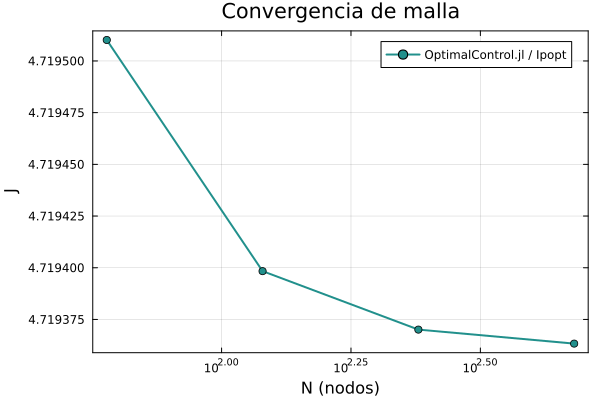

In [ ]:
Ns = [60, 120, 240, 480]
Js = [postproceso(resolver_ocp(N = n)).Jsol for n in Ns]
@printf("\nConvergencia de malla: %s\n", join([@sprintf("N=%d → J=%.5f", n, j) for (n, j) in zip(Ns, Js)], " | "))
fig_malla = plot(Ns, Js; marker = :circle, xlabel = "N (nodos)", ylabel = "J",
                 title = "Convergencia de malla", label = "OptimalControl.jl / Ipopt", xscale = :log10,
                 color = COL_K)
savefig(fig_malla, joinpath(FIG, "fig_malla.png"));
display(fig_malla)

## 8. Función valor y ecuación HJB

Apreciamos que para la función valor,
$$
V(t,x)=\sup_{u(\cdot)}\int_t^T e^{-\rho(s-t)}L\big(x(s),u(s)\big)\,ds,\qquad x(t)=x,\qquad V(T,\cdot)\equiv 0,
$$
con $L(x,u)=\log(1+ck)-\tfrac{\chi}{2}M^2-\tfrac{q_1}{2}u_1^2-\tfrac{q_2}{2}u_2^2$.

Para la ecuación HJB
$$
\rho V - V_t=\max_{u\in U}\Big\{L(x,u)+V_k\,f_1(x,u)+V_M\,f_2(x,u)\Big\},
$$
y la política en lazo cerrado es el argumento del máximo, $u^*(t,x)$.

Las ecuaciones de estado y co-estado del PMP son las características de la HJB, con
$$
\mu(t)=\nabla_x V\big(t,x^*(t)\big),\qquad \mu(T)=\nabla_xV(T,\cdot)=0 .
$$
El PMP entrega condiciones **necesarias** a lo largo de una trayectoria mientras que la HJB entrega la política para todo estado y permite verificar optimalidad global.

Sobre el cálculo numérico, al ser el estado de dimensión 2, la HJB puede resolverse por programación dinámica hacia atrás desde $V(T,\cdot)=0$ sobre una grilla en $(k,M)$ (Euler en el tiempo, controles en una grilla de paso $0.1$, interpolación bilineal). El código trabaja en valor presente, que en $t=0$ coincide con el valor corriente.

In [ ]:
function interpolar(V, ks, Ms, k, M)
    i = clamp(searchsortedlast(ks, k), 1, length(ks) - 1)
    j = clamp(searchsortedlast(Ms, M), 1, length(Ms) - 1)
    x = clamp((k - ks[i]) / (ks[i+1] - ks[i]), 0.0, 1.0)
    y = clamp((M - Ms[j]) / (Ms[j+1] - Ms[j]), 0.0, 1.0)
    return (1 - x) * (1 - y) * V[i, j]   + x * (1 - y) * V[i+1, j] +
           (1 - x) * y       * V[i, j+1] + x * y       * V[i+1, j+1]
end

function calcular_hjb(; nk = 53, nM = 41, Nt = 180)
    ks = collect(range(0.0, 4.2;  length = nk))
    Ms = collect(range(0.0, 1.85; length = nM))
    dt = T / Nt
    V = zeros(nk, nM)
    W = similar(V)
    politica = zeros(nk, nM)                 # u1 óptimo en t = 0

    for n in Nt:-1:1
        t = (n - 1) * dt
        for i in eachindex(ks), j in eachindex(Ms)
            k = ks[i]; M = Ms[j]
            mejor = -Inf; fosil_optimo = 0.0
            for u1 in 0:0.1:1, u2 in 0:0.1:1
                k2 = k + dt * (a * k / (1 + k) * (u1 + eta * u2) - (c + delta) * k)
                M2 = M + dt * (beta * u1 - sigma * M)
                Lt = exp(-rho * t) * (log(1 + c * k) - CHI * M^2 / 2 - q1 * u1^2 / 2 - q2 * u2^2 / 2)
                valor = dt * Lt + interpolar(V, ks, Ms, k2, M2)
                if valor > mejor
                    mejor = valor
                    fosil_optimo = u1
                end
            end
            W[i, j] = mejor
            n == 1 && (politica[i, j] = fosil_optimo)
        end
        V, W = W, V
    end
    return ks, Ms, V, politica
end

ks, Ms, V, politica = calcular_hjb()
V0(k, M) = interpolar(V, ks, Ms, k, M)

@printf("V(0, x0) ≈ %.4f   (programación dinámica, HJB)\n", V0(x0...))
@printf("J        = %.4f   (OptimalControl.jl, PMP)\n", base.Jsol)

V(0, x0) ≈ 4.7162   (programación dinámica, HJB)
J        = 4.7194   (OptimalControl.jl, PMP)


Analizamos la relación $\mu=\nabla V$. Se compara el gradiente de la función valor en $(0,x_0)$, aproximado por diferencias finitas centradas sobre la grilla, con los co-estados iniciales $\mu(0)$ que entrega el PMP. Se espera concordancia aproximada, limitada por la resolución de la grilla.

                   ∇V (HJB)     μ(0) (PMP)
∂V/∂k  =       0.8713       0.8464
∂V/∂M  =      -1.1081      -1.1064


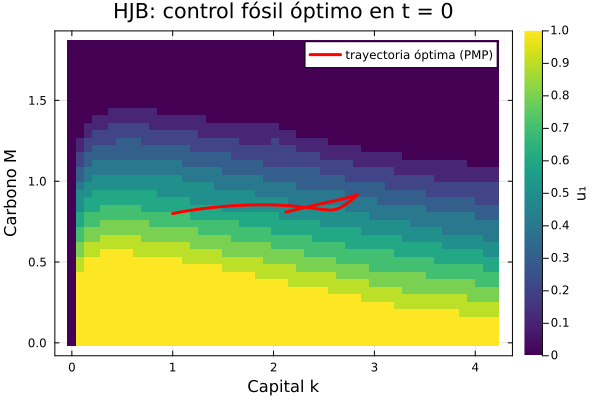

In [ ]:
hk, hM = ks[2] - ks[1], Ms[2] - Ms[1]
dVdk = (V0(x0[1] + hk, x0[2]) - V0(x0[1] - hk, x0[2])) / (2hk)
dVdM = (V0(x0[1], x0[2] + hM) - V0(x0[1], x0[2] - hM)) / (2hM)

println("                   ∇V (HJB)     μ(0) (PMP)")
@printf("∂V/∂k  = %12.4f %12.4f\n", dVdk, base.mu[1, 1])
@printf("∂V/∂M  = %12.4f %12.4f\n", dVdM, base.mu[2, 1])

# Política fósil óptima en t = 0 y trayectoria óptima del PMP sobre el plano (k, M)
p_hjb = heatmap(ks, Ms, politica'; xlabel = "Capital k", ylabel = "Carbono M",
                title = "HJB: control fósil óptimo en t = 0", colorbar_title = "u₁",
                color = :viridis)
plot!(p_hjb, base.k, base.M; color = :red, lw = 3, label = "trayectoria óptima (PMP)")
savefig(p_hjb, joinpath(FIG, "hjb_politica_fosil.png"))
display(p_hjb)

## 9. Conclusiones

- **Verificación cruzada.** La solución numérica con `OptimalControl.jl` es coherente con el PMP (controles y co-estados reconstruidos) y con la HJB (valor $V(0,x_0)$ y gradiente $\nabla V\approx\mu(0)$).
- **Estructura de la política.** Con costos cuadráticos en los controles, el máximo del Hamiltoniano es único y los controles son continuos: no hay arcos bang-bang. La inversión renovable alcanza la cota $u_2=1$ durante la mayor parte del horizonte, mientras que el uso fósil es interior y se determina por la diferencia entre su aporte productivo y su costo climático $\beta\,|\mu_M|$.
- **Precio sombra del carbono.** $\mu_M<0$ cuantifica el daño futuro de una unidad adicional de carbono, el costo social $-\mu_M/\mu_k$ es el precio al que la economía debería valorar las emisiones.
- **Sensibilidad climática.** Un daño $\chi$ mayor reduce el uso fósil y el carbono final a costa de capital y bienestar; un tope al uso fósil permite comparar políticas de mitigación con distinto costo.
- **Efecto de horizonte finito.** Como el estado final es libre y no hay valor terminal, $\mu(T)=0$ y ambos controles se anulan al final del horizonte. Es una consecuencia de la formulación, no una recomendación de política de largo plazo.
- **Alcance.** Los parámetros y las formas funcionales son ilustrativos. Los resultados son óptimos locales según el PMP y se contrastan con la HJB resuelta en una grilla, para otras calibraciones conviene repetir el análisis.